# Longest path of shortest hate


In [5]:
from src.utils.data_utils import load_reddit_graph
import random
import numpy as np

G = load_reddit_graph()
random.seed(42)
np.random.seed(42)

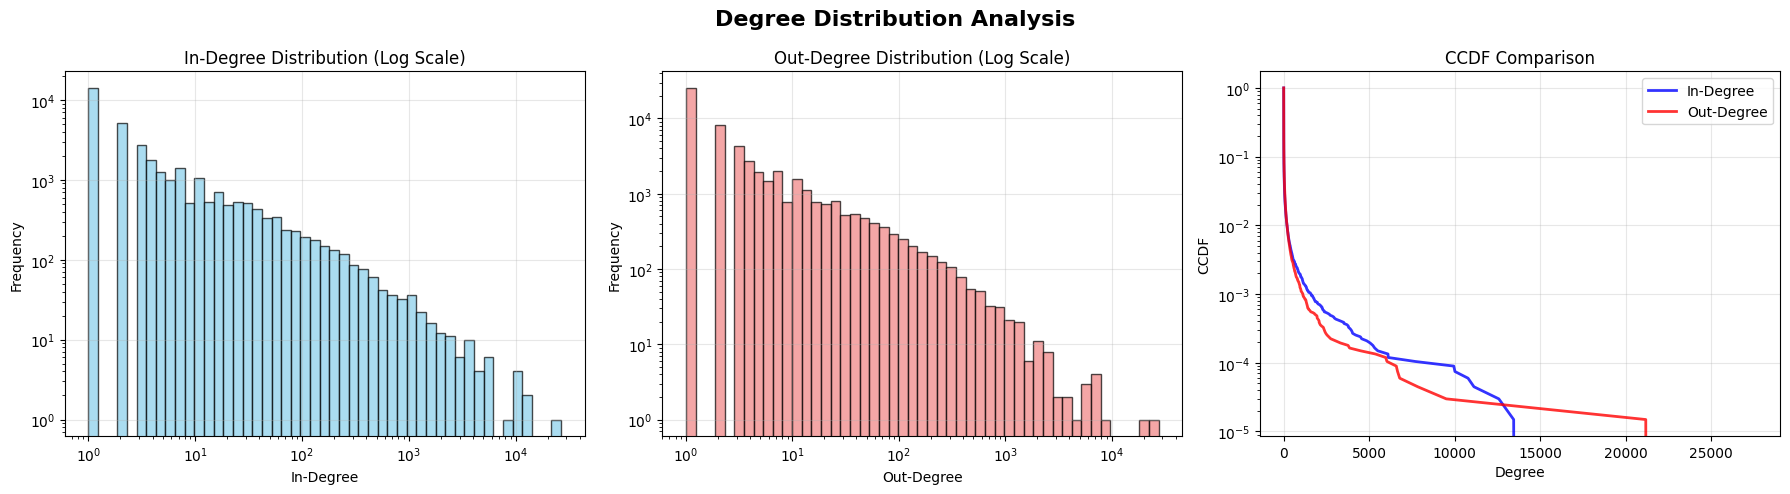

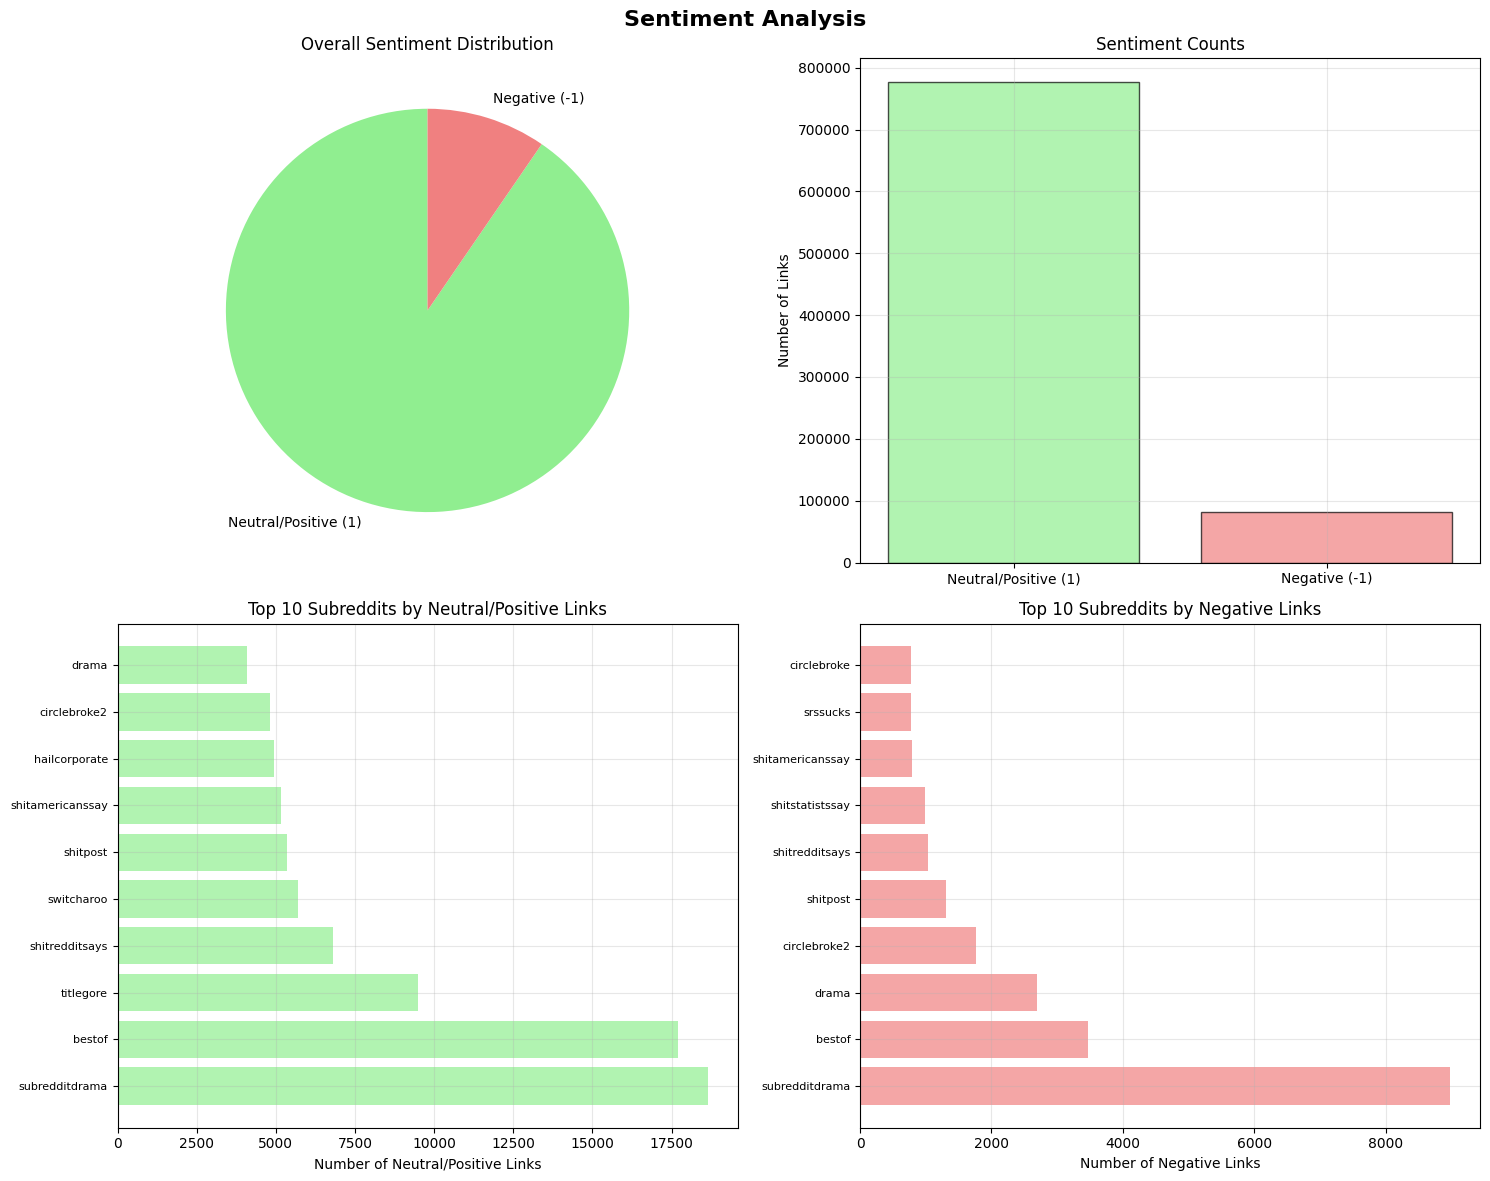

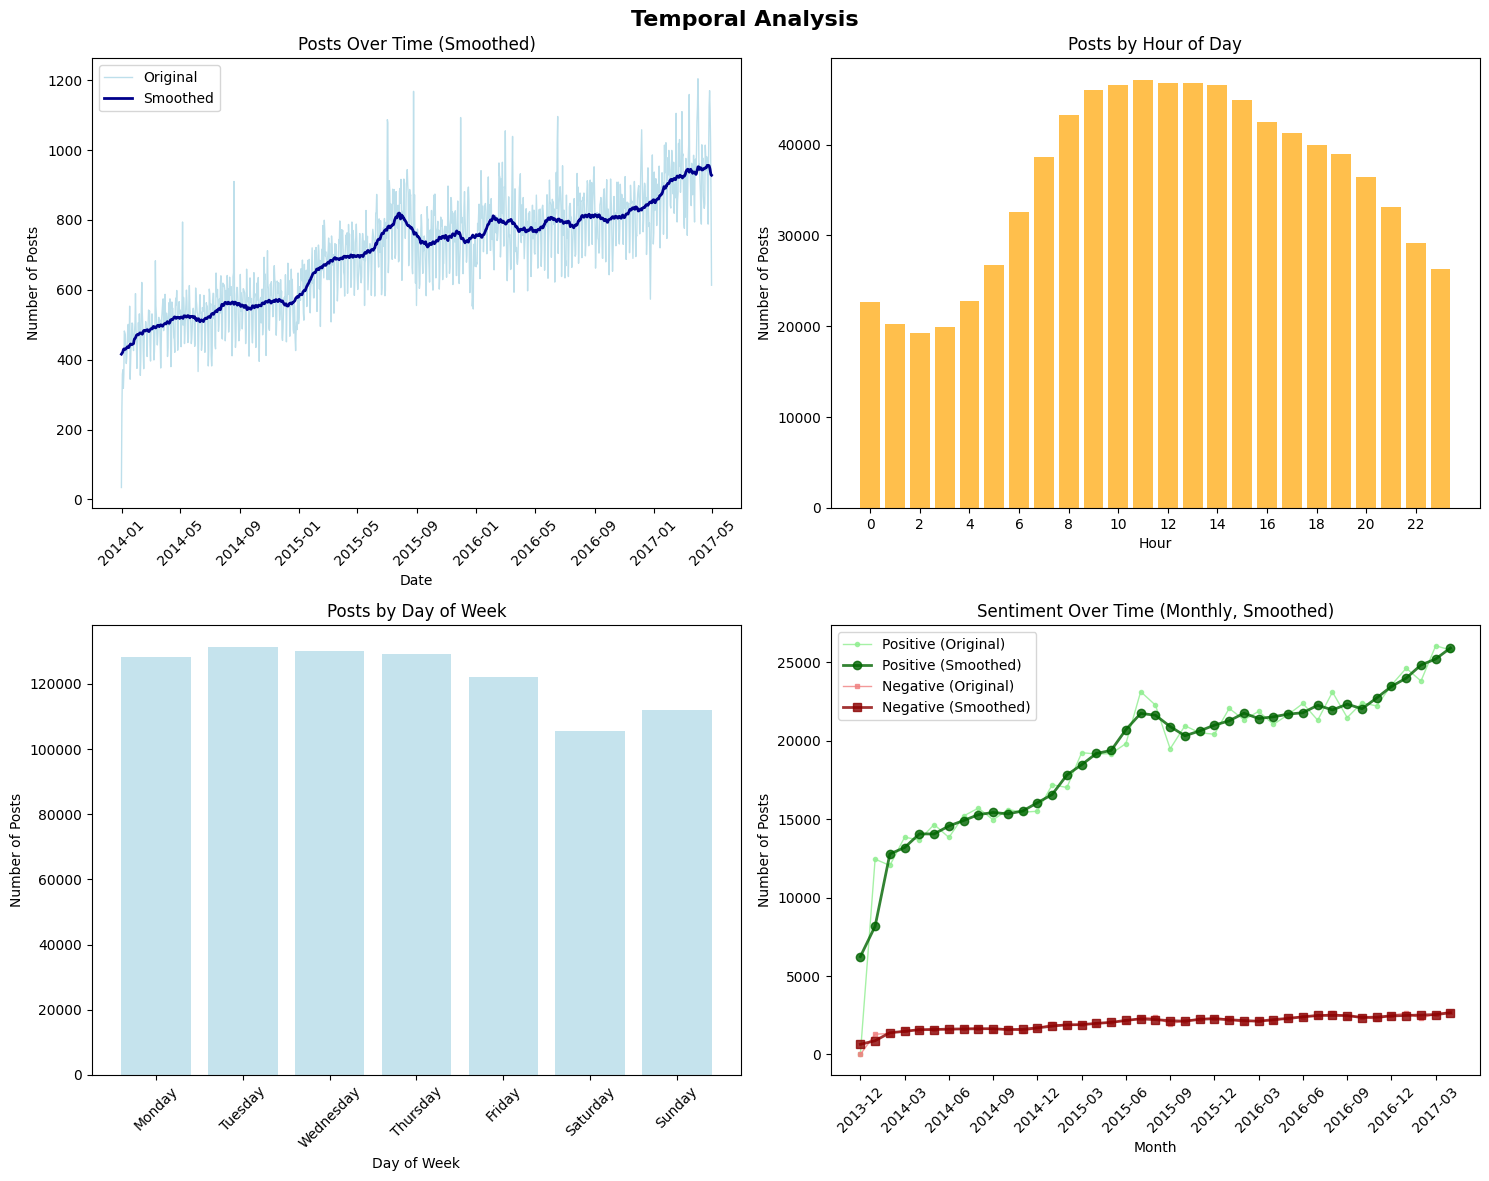

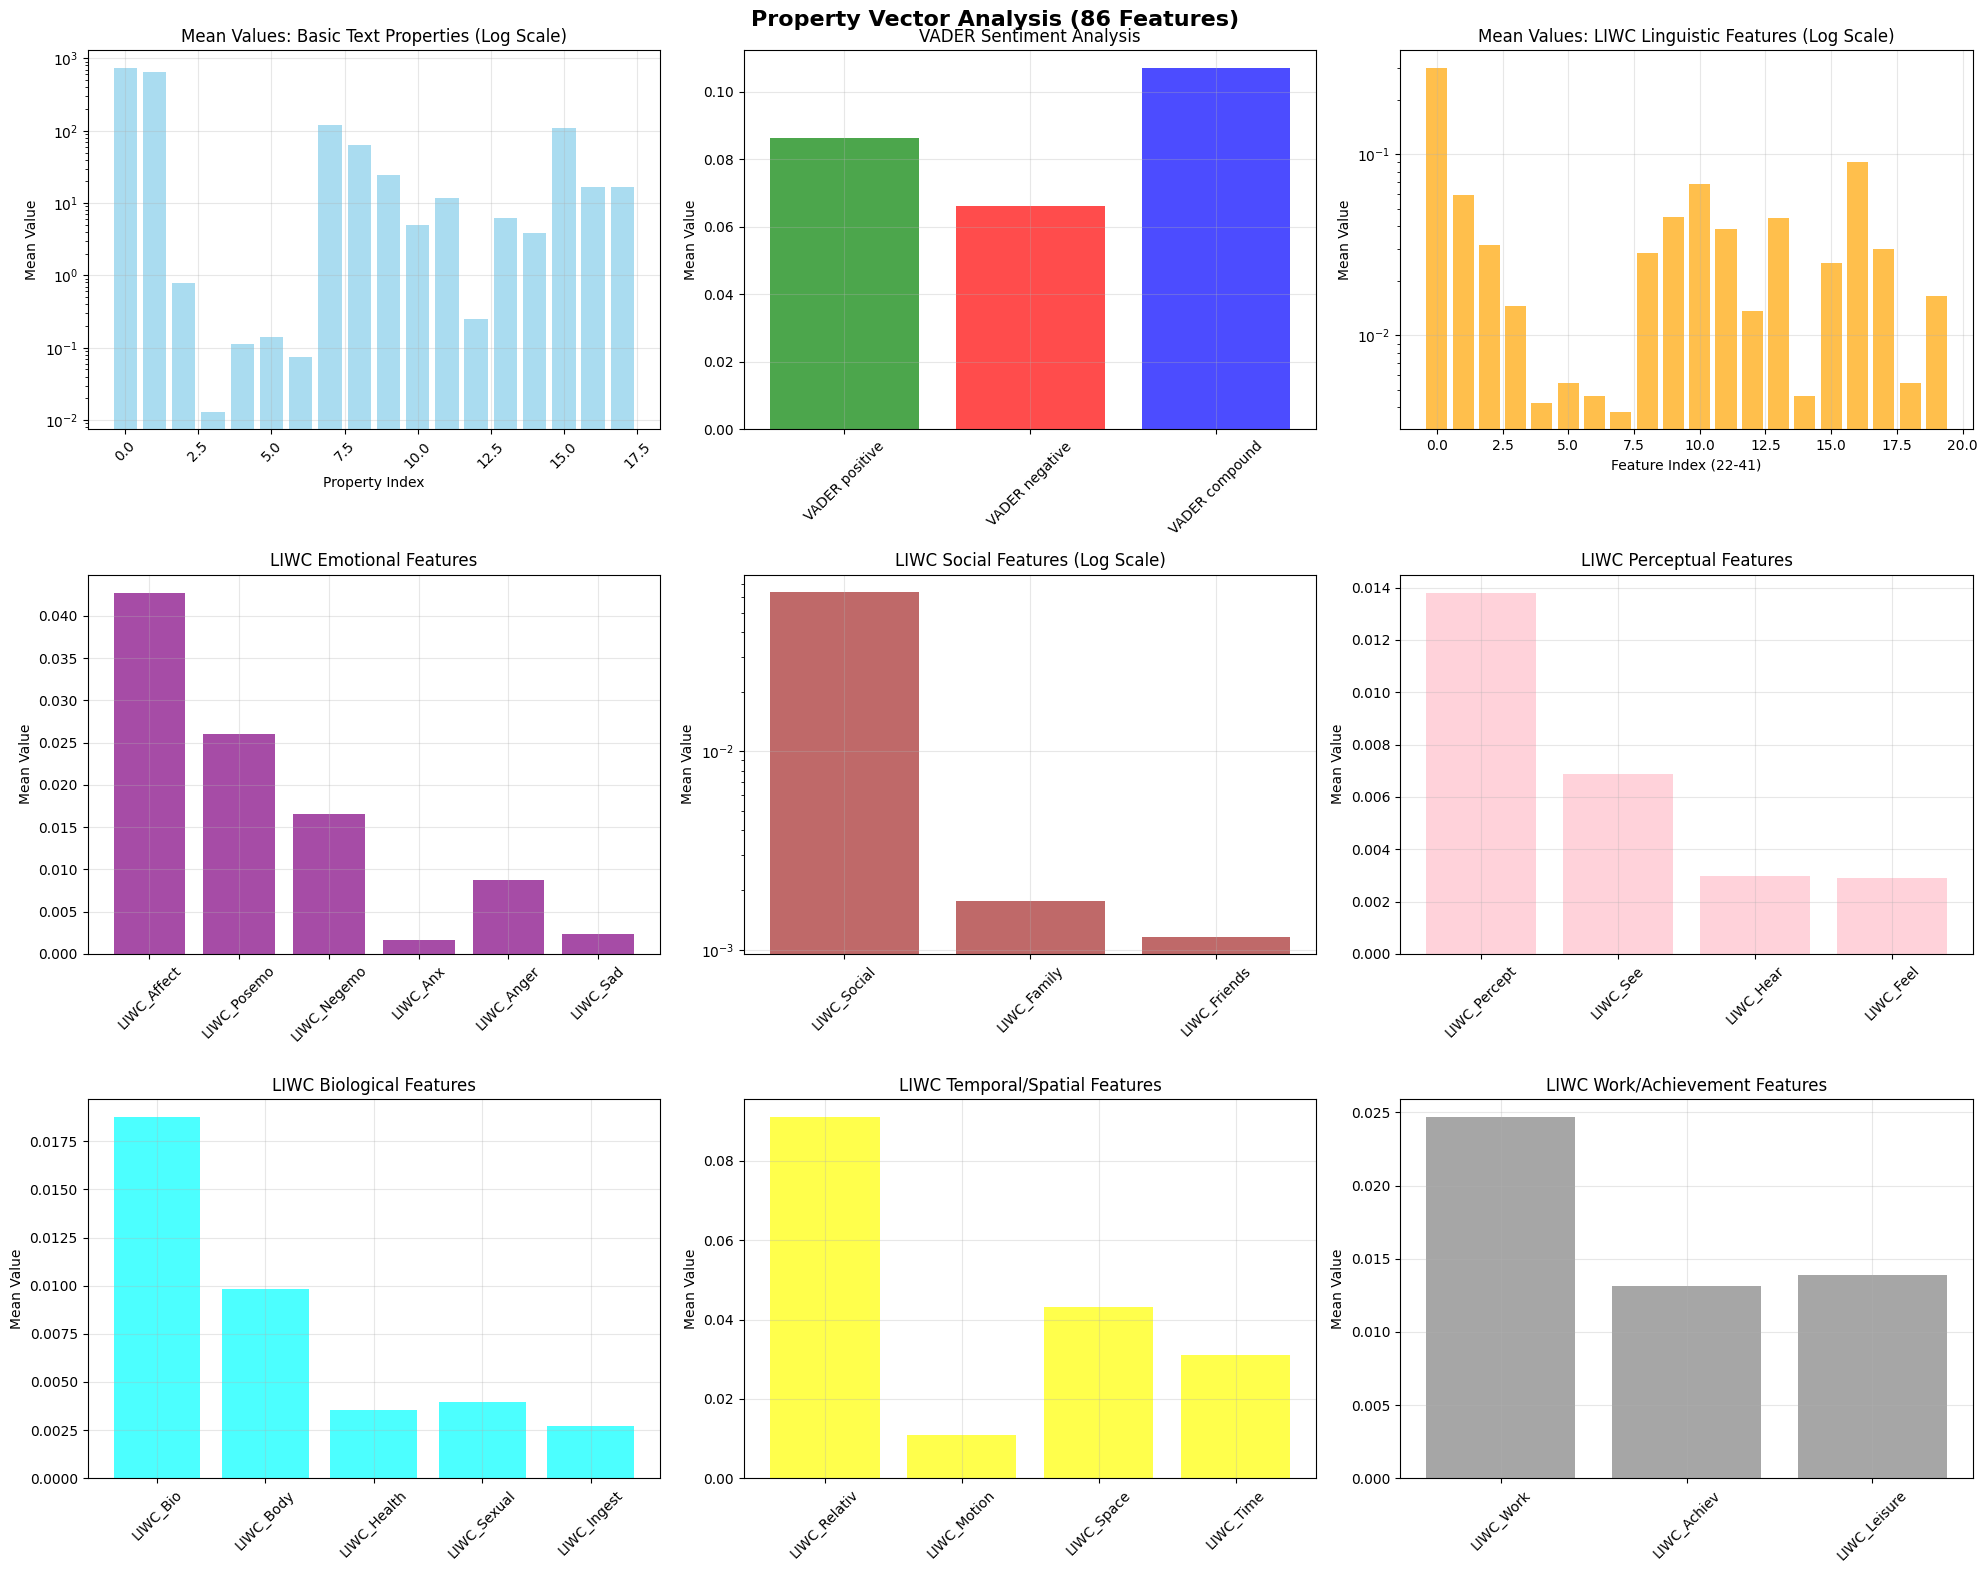

In [6]:
from src.analysis.init_analysis import plot_degree_distribution, \
    plot_sentiment_analysis, plot_temporal_analysis, \
    plot_property_vector_analysis

plot_degree_distribution(G, show=True)
plot_sentiment_analysis(G, show=True)
plot_temporal_analysis(G, show=True)
plot_property_vector_analysis(G, show=True)

In [7]:
from src.utils.data_utils import load_reddit_graph
import random
import numpy as np

G = load_reddit_graph()
random.seed(42)
np.random.seed(42)

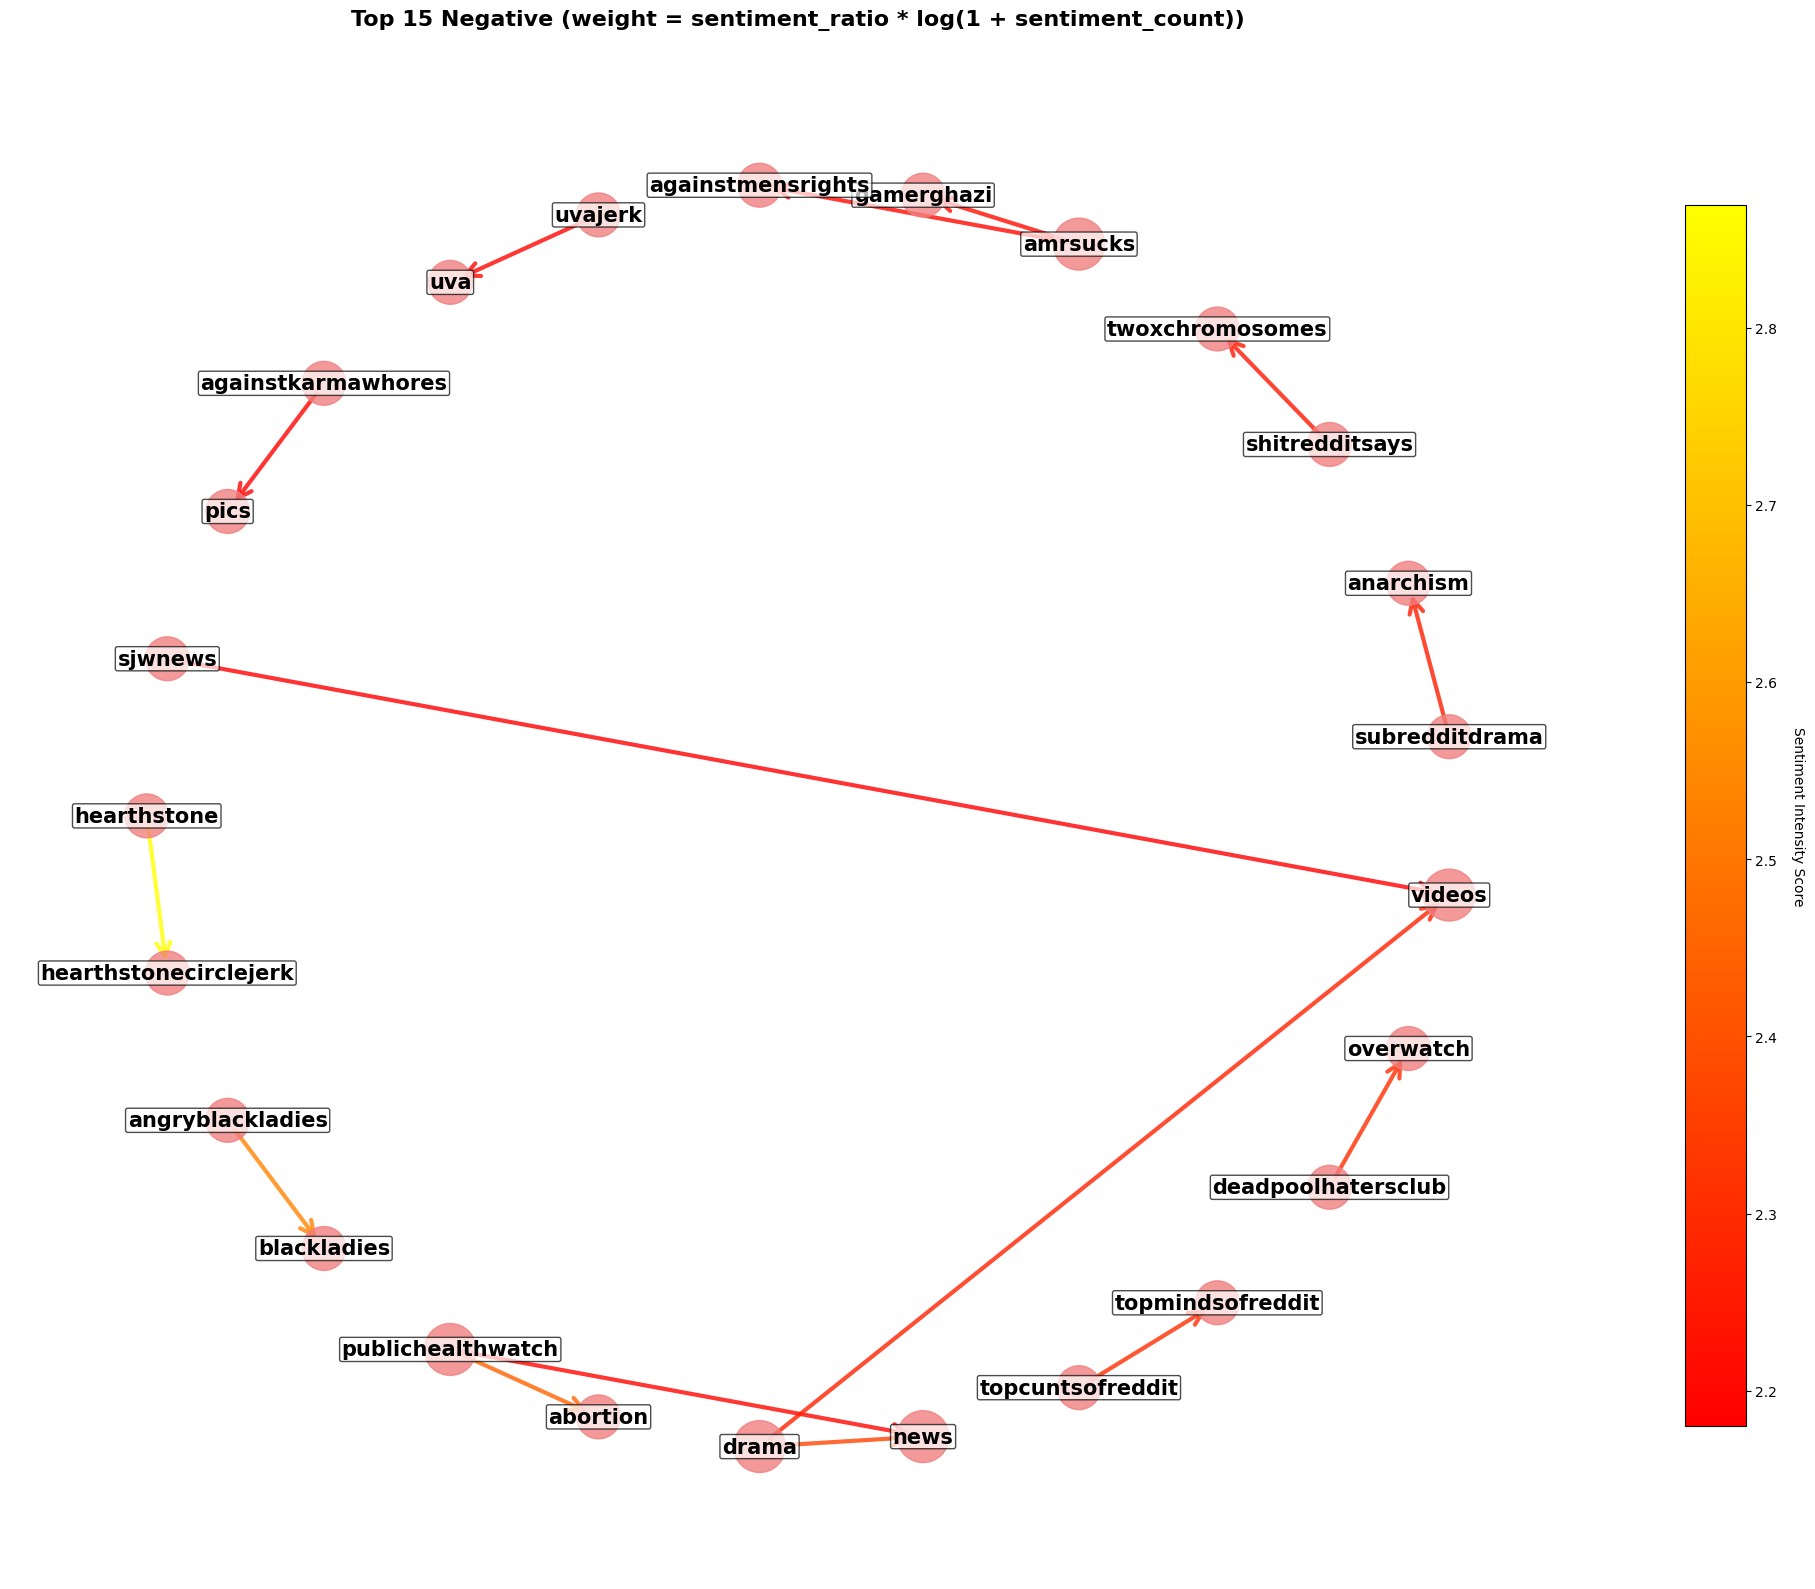

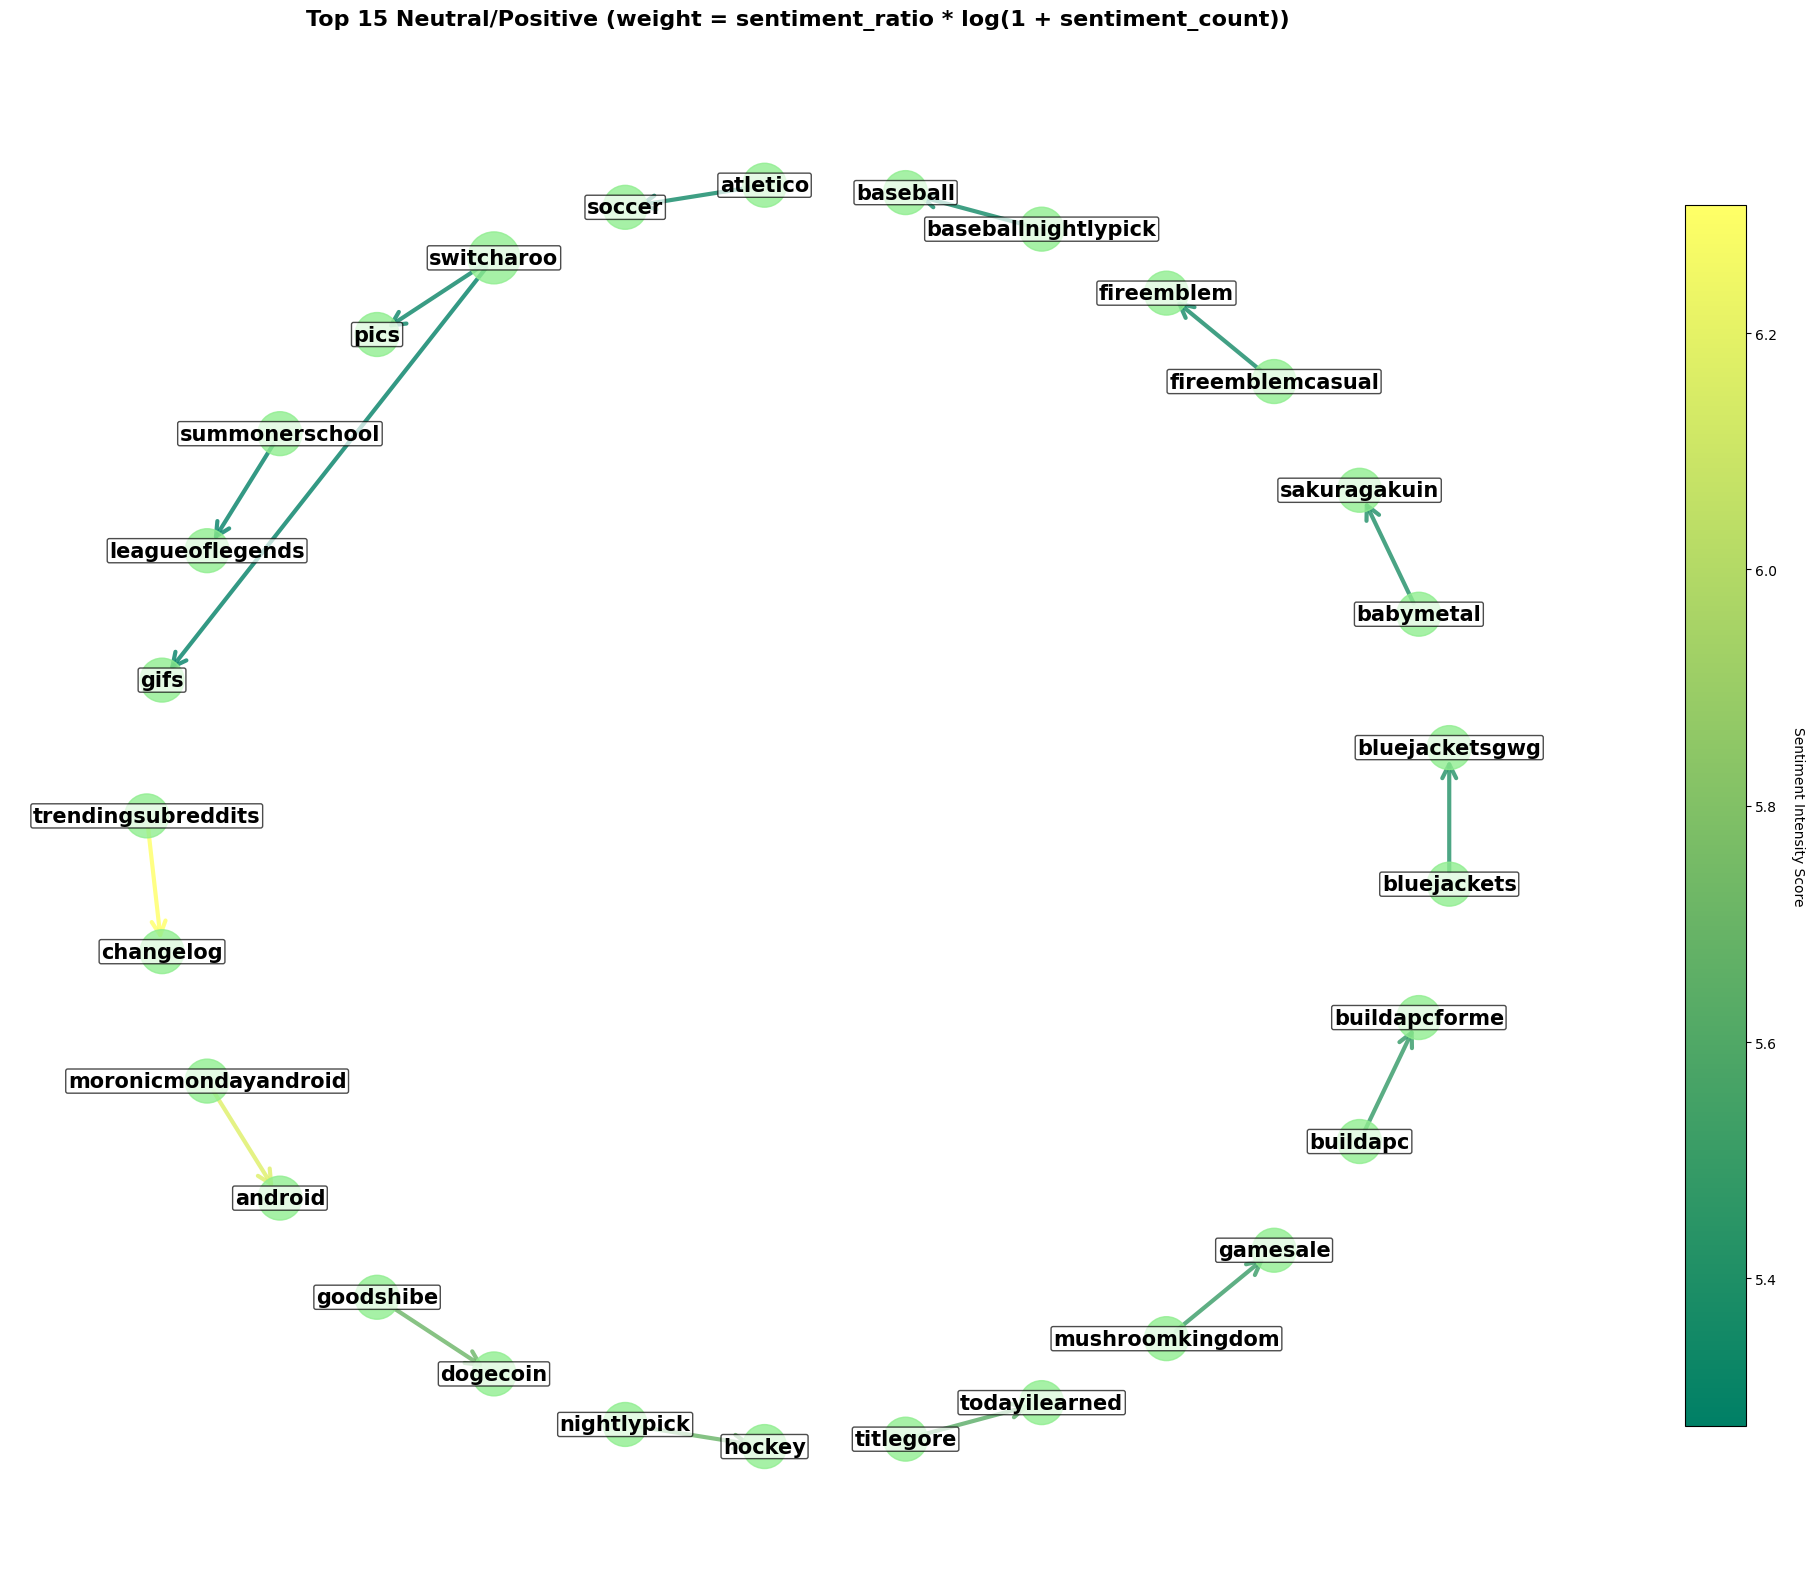

In [8]:
from src.analysis.create_sentiment_graph import create_and_visualize_graph

# Note: 'sentiment_intensity' is the best metric to visualize imo

# NEGATIVE SENTIMENT
# create_and_visualize_graph(G, 'negative_frequency', top_n=30, show=True)
# create_and_visualize_graph(G, 'relative_negative', top_n=30, show=True)
create_and_visualize_graph(G, 'sentiment_intensity', sentiment='neg', top_n=15, show=True)
# create_and_visualize_graph(G, 'negative_count', top_n=30, show=True)
# create_and_visualize_graph(G, 'source_total_negative', top_n=30, show=True)
# create_and_visualize_graph(G, 'source_activity_weighted', top_n=30, show=True)
# create_and_visualize_graph(G, 'target_activity_weighted', top_n=30, show=True)
# create_and_visualize_graph(G, 'combined_activity', top_n=30, show=True)
# create_and_visualize_graph(G, 'subreddit_size_ratio', top_n=30, show=True)

# POSITIVE SENTIMENT
create_and_visualize_graph(G, 'sentiment_intensity', sentiment='pos', top_n=15, show=True)

In [9]:
from src.utils.data_utils import load_reddit_graph
import random
import numpy as np

G = load_reddit_graph()
random.seed(42)
np.random.seed(42)

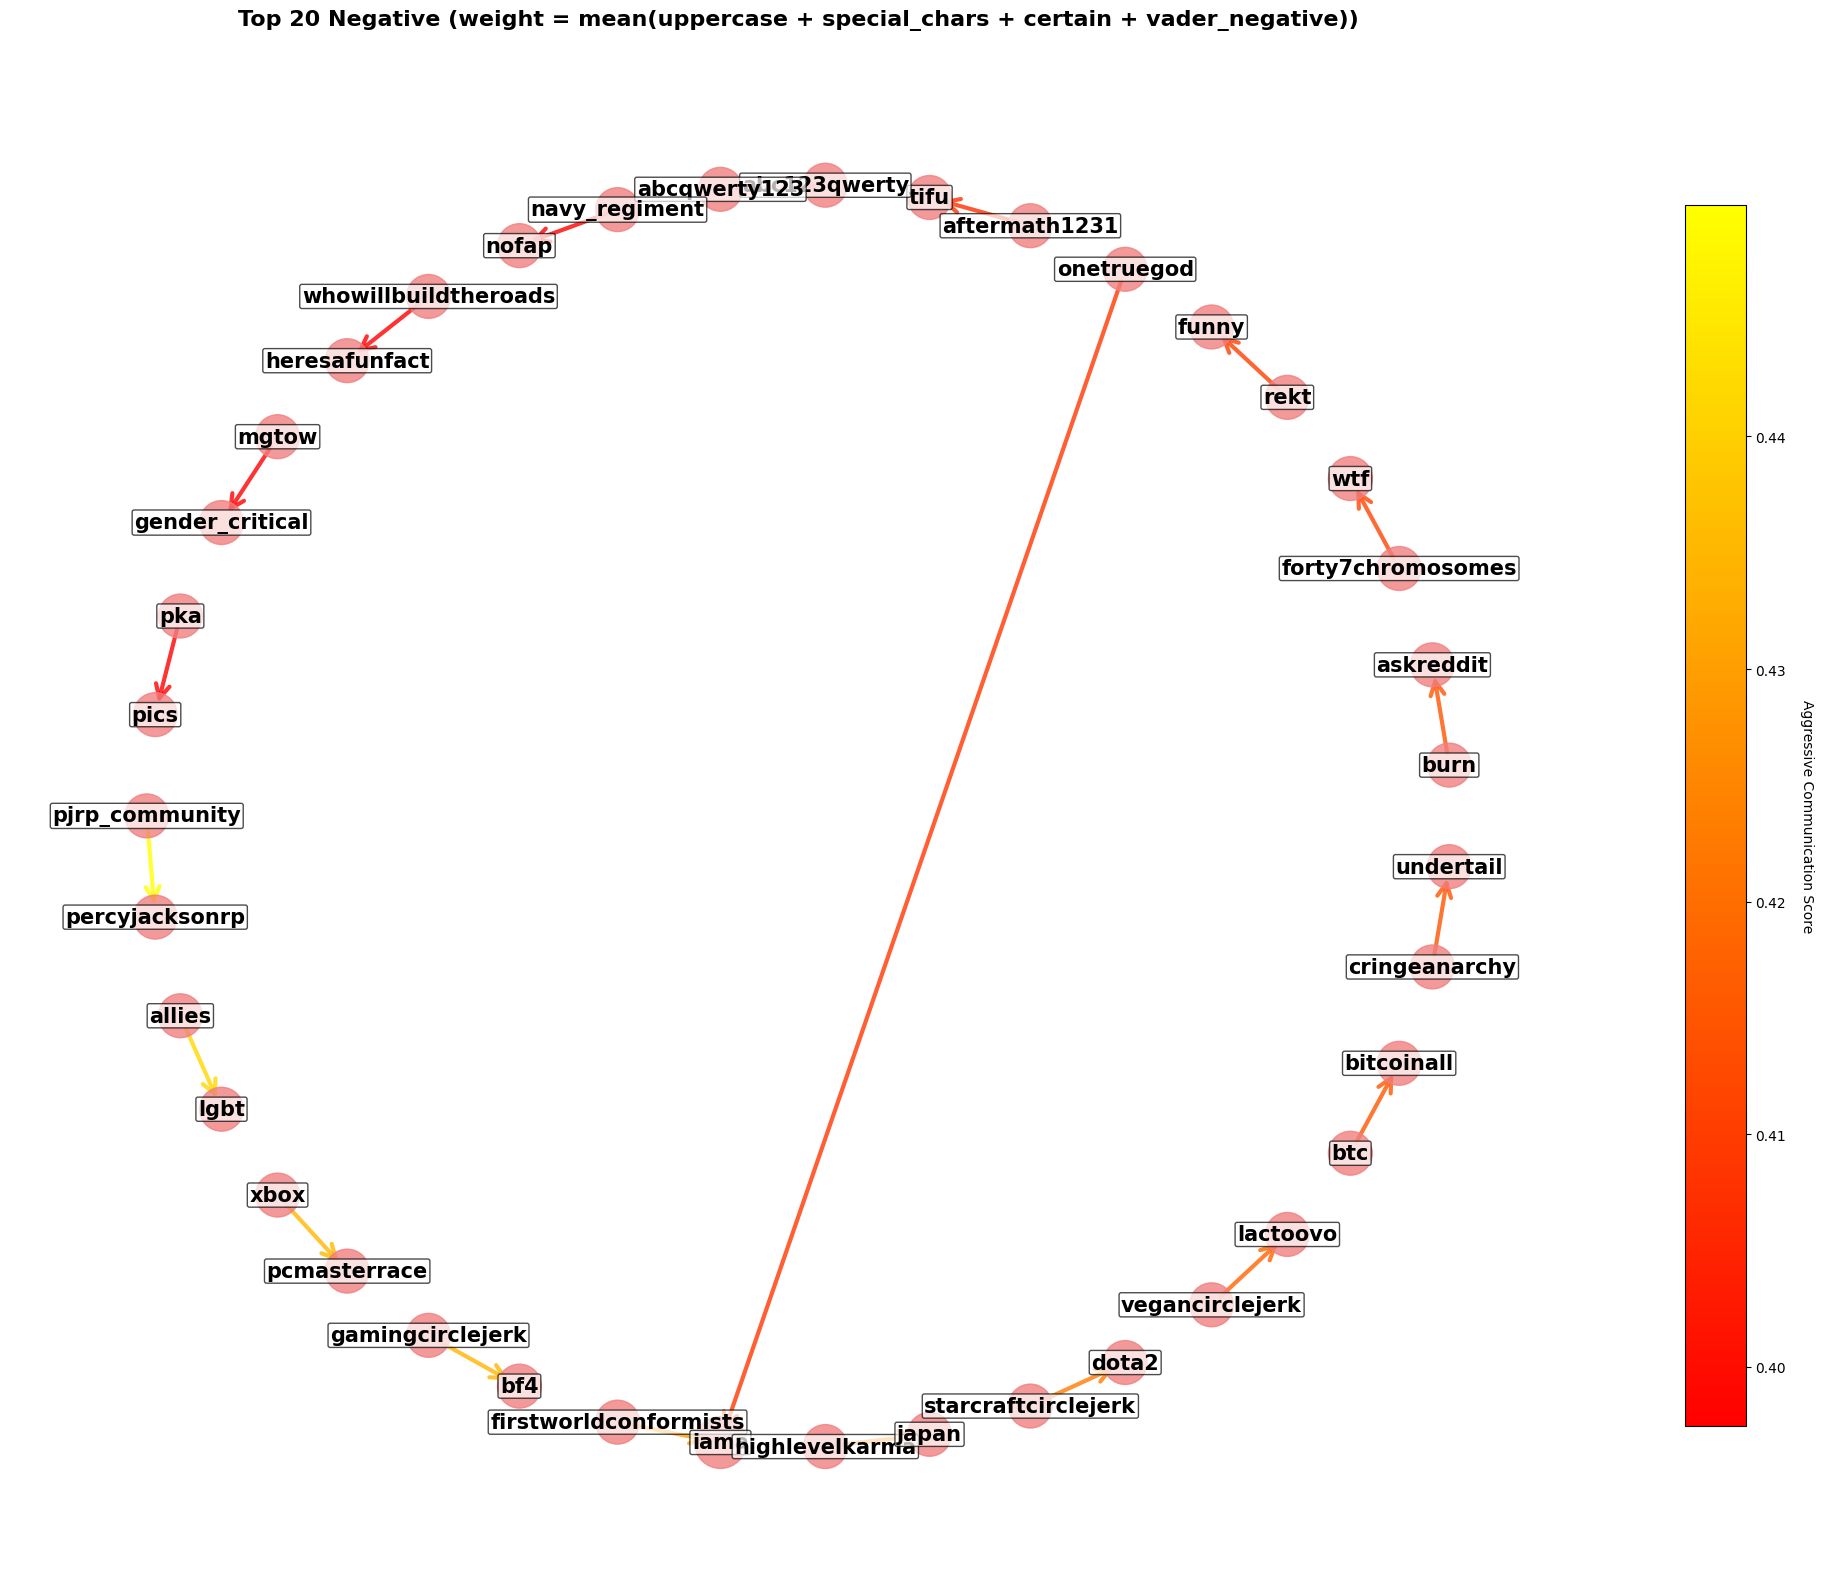

In [10]:
from src.analysis.create_sentiment_graph import create_and_visualize_graph

# The second metric is the most descriptive imo

# create_and_visualize_graph(G, 'direct_hate_score', sentiment='neg', top_n=20, show=True)
create_and_visualize_graph(G, 'aggressive_communication', sentiment='neg', top_n=20, show=True)
# create_and_visualize_graph(G, 'emotional_toxicity', sentiment='neg', top_n=20, show=True)
# create_and_visualize_graph(G, 'social_conflict', sentiment='neg', top_n=20, show=True)
# create_and_visualize_graph(G, 'comprehensive_hate', sentiment='neg', top_n=20, show=True)
# create_and_visualize_graph(G, 'hate_intensity_weighted', sentiment='neg', top_n=20, show=True)
# create_and_visualize_graph(G, 'sentiment_intensity', sentiment='neg', top_n=20, show=True)

In [11]:
from src.utils.data_utils import load_reddit_graph
import random
import numpy as np

G = load_reddit_graph()
random.seed(42)
np.random.seed(42)

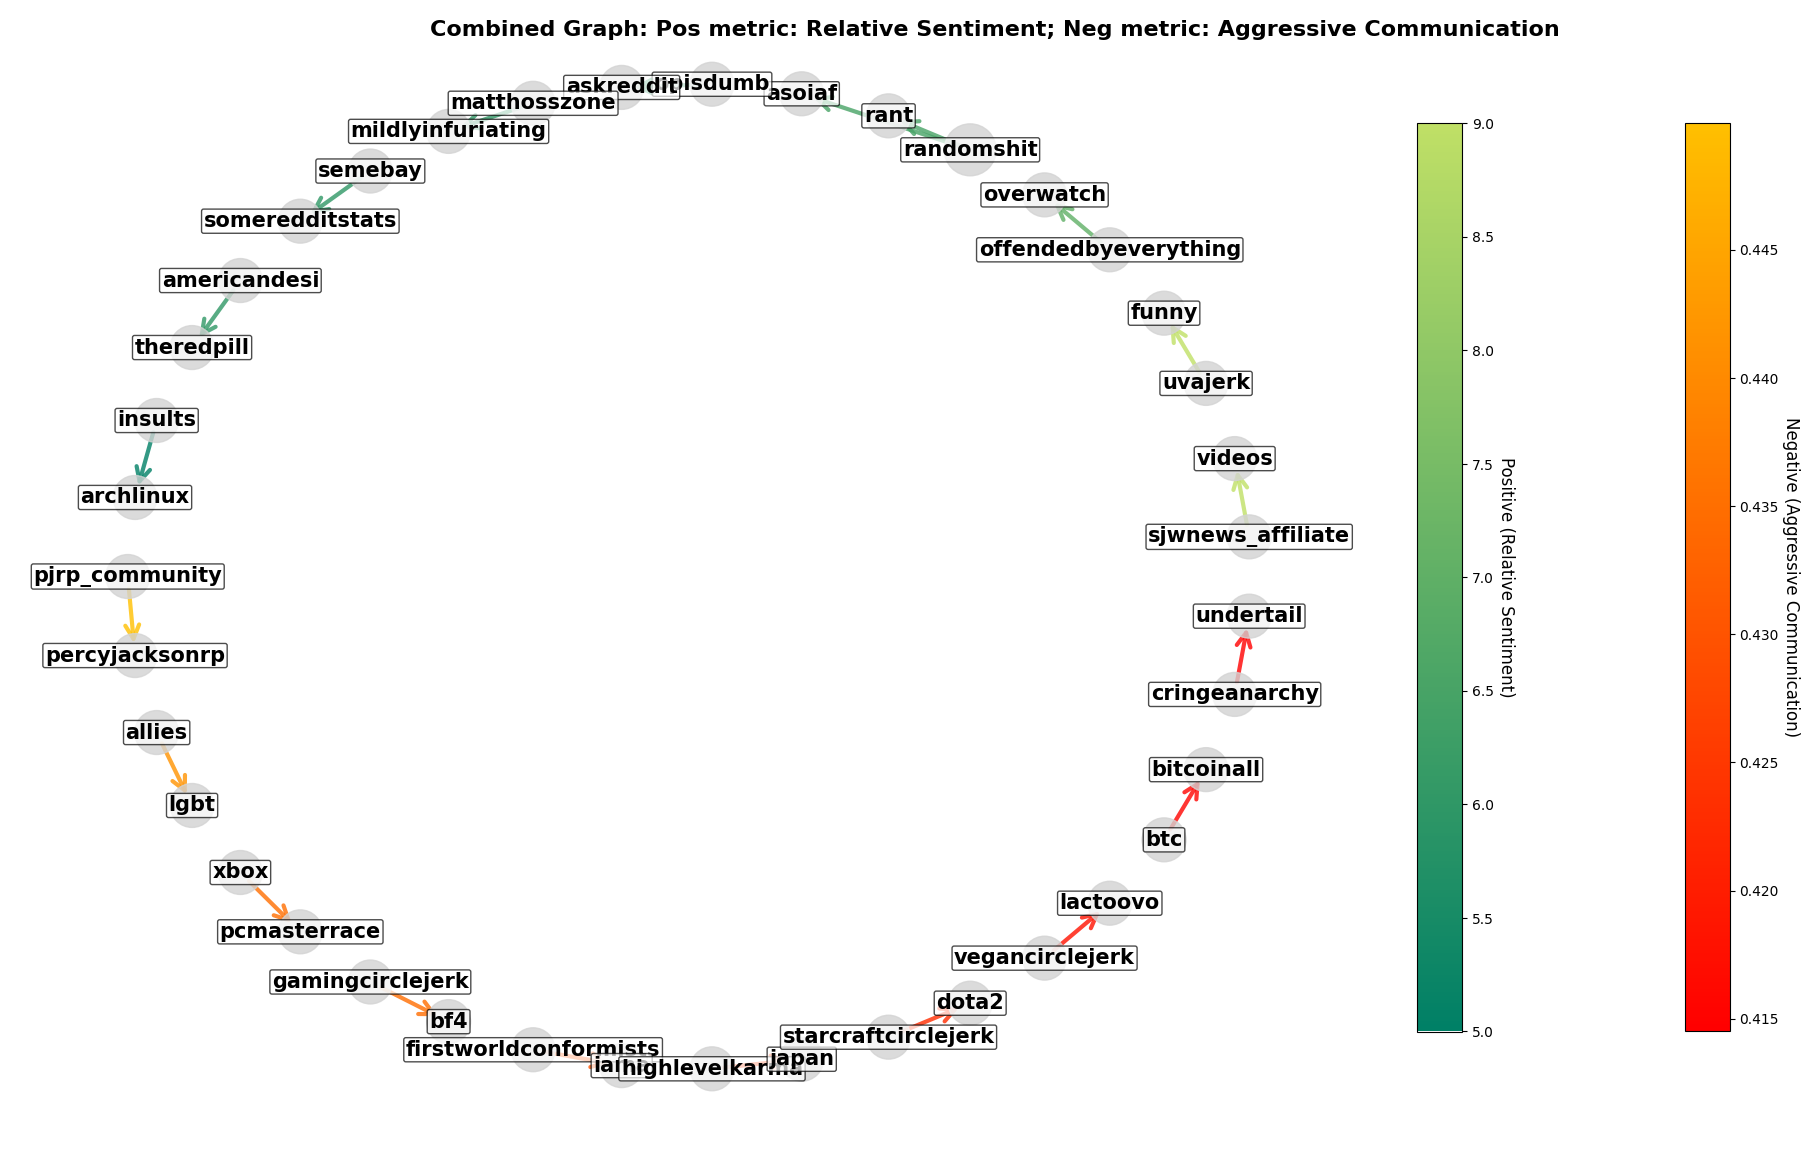

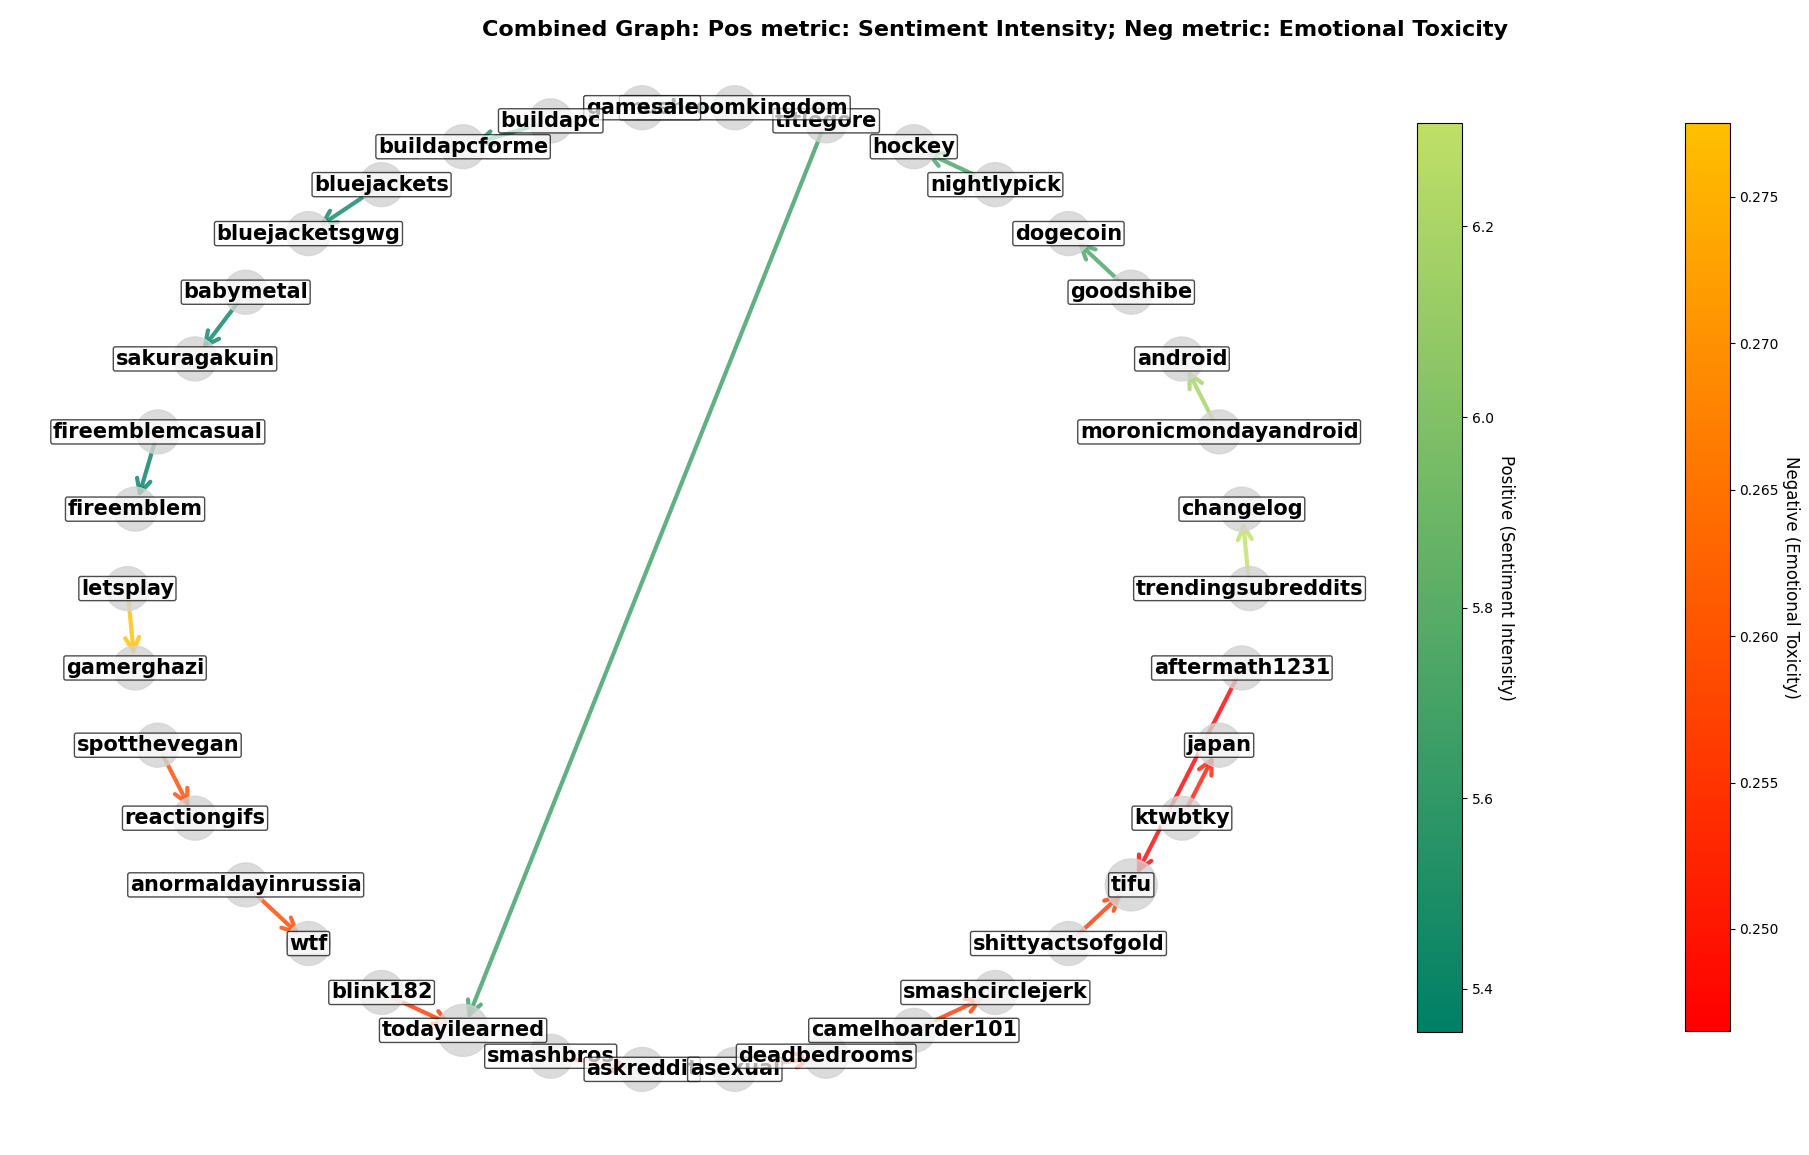

In [12]:
from src.analysis.create_sentiment_graph import create_and_visualize_combined_graph

# create_and_visualize_combined_graph(G, metric_pos='sentiment_ratio', metric_neg='sentiment_ratio', top_n_neg=10, top_n_pos=10, show=True)
# create_and_visualize_combined_graph(G, metric_pos='sentiment_frequency', metric_neg='direct_hate_score', top_n_neg=10, top_n_pos=10, show=True)
create_and_visualize_combined_graph(G, metric_pos='relative_sentiment', metric_neg='aggressive_communication', top_n_neg=10, top_n_pos=10, show=True)
create_and_visualize_combined_graph(G, metric_pos='sentiment_intensity', metric_neg='emotional_toxicity', top_n_neg=10, top_n_pos=10, show=True)
# create_and_visualize_combined_graph(G, metric_pos='sentiment_count', metric_neg='social_conflict', top_n_neg=10, top_n_pos=10, show=True)


## Analysis of top subreddits' LIWC features

In [13]:
import src.analysis.top_subreddits_analysis as tsa

top_in_degree, top_out_degree = tsa.find_highest_node_degrees(G)


Top 10 nodes with highest IN-DEGREE:
Node (Subreddit)		In-Degree
--------------------------------------------------
askreddit                     	26622
iama                          	13446
pics                          	12578
todayilearned                 	11124
funny                         	10777
videos                        	10013
worldnews                     	9944
news                          	7692
politics                      	6114
gaming                        	6097

Top 10 nodes with highest OUT-DEGREE:
Node (Subreddit)		Out-Degree
--------------------------------------------------
subredditdrama                	27636
bestof                        	21170
titlegore                     	9503
shitredditsays                	7839
drama                         	6784
shitpost                      	6658
circlebroke2                  	6583
switcharoo                    	6039
shitamericanssay              	5963
hailcorporate                 	5360


In [14]:
high_degree_edges, high_degree_edges_unique = tsa.analyze_edge_patterns(G)

In-degree threshold for 90th percentile: 9.0
Out-degree threshold for 90th percentile: 14.0

Found 682837 edges connecting high-degree nodes...

Found 207312 unique source-target edges connecting high-degree nodes...



High-degree edges:
           source     target  source_out_degree  target_in_degree  sentiment  \
0  subredditdrama  askreddit              27636             26622          1   
1  subredditdrama  askreddit              27636             26622         -1   
2  subredditdrama  askreddit              27636             26622          1   
3  subredditdrama  askreddit              27636             26622          1   
4  subredditdrama  askreddit              27636             26622          1   
5  subredditdrama  askreddit              27636             26622         -1   
6  subredditdrama  askreddit              27636             26622         -1   
7  subredditdrama  askreddit              27636             26622          1   
8  subredditdrama  askreddit             

In [15]:
top_subreddits = [node for node, _ in top_in_degree[:20]] + [node for node, _ in top_out_degree[:20]]
top_subreddits = list(set(top_subreddits))
liwc_df = tsa.extract_liwc_features(G, top_subreddits)

These are the covariance and correlation matrices for LIWC features of the top 20 subreddits. It shows which LIWC feature pairs are most commonly occurring.

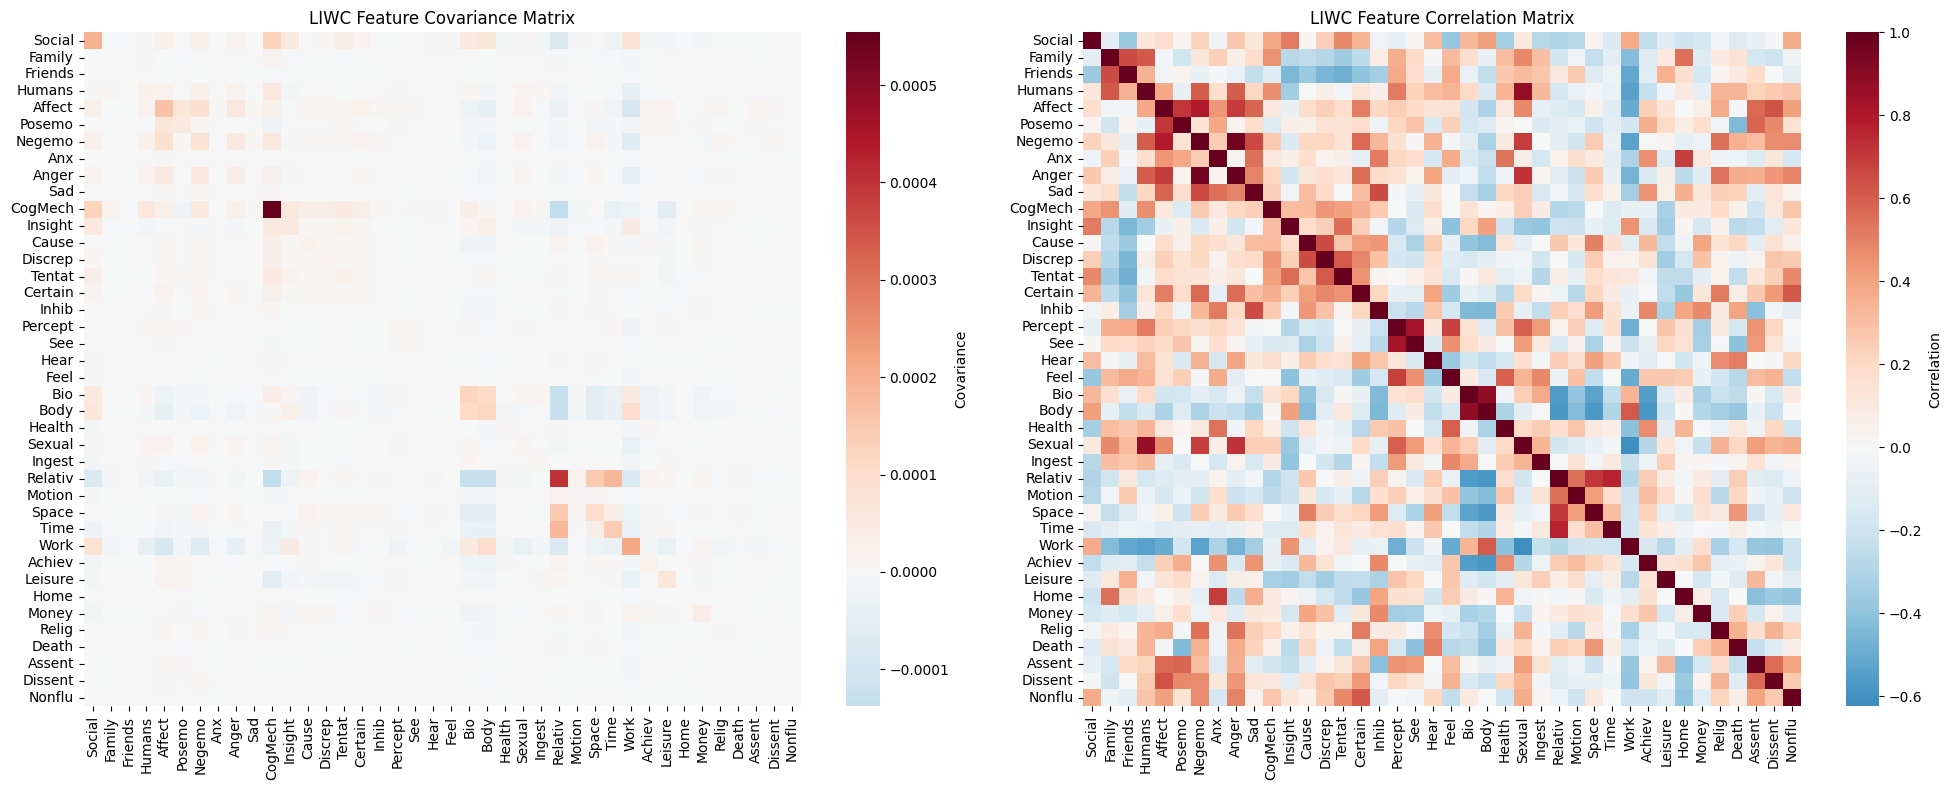

(               LIWC_Social   LIWC_Family  LIWC_Friends   LIWC_Humans  \
 LIWC_Social   1.988421e-04 -3.176615e-06 -5.005423e-06  8.858122e-06   
 LIWC_Family  -3.176615e-06  4.865669e-06  1.384107e-06  7.170763e-06   
 LIWC_Friends -5.005423e-06  1.384107e-06  9.359923e-07  1.771260e-06   
 LIWC_Humans   8.858122e-06  7.170763e-06  1.771260e-06  2.791472e-05   
 LIWC_Affect   3.023540e-05 -7.939613e-07 -4.457530e-07  2.574855e-05   
 LIWC_Posemo   2.610621e-06 -3.105353e-06  2.285305e-07 -3.073958e-06   
 LIWC_Negemo   2.926765e-05  2.283545e-06 -7.119456e-07  2.867211e-05   
 LIWC_Anx     -1.090377e-06  6.914365e-07 -2.406600e-08  1.149172e-06   
 LIWC_Anger    2.394607e-05  8.635297e-07 -3.827285e-07  2.044541e-05   
 LIWC_Sad      2.057544e-06  4.870572e-07 -2.893593e-07  1.338752e-06   
 LIWC_CogMech  1.293289e-04  2.292890e-05 -2.797777e-06  5.731027e-05   
 LIWC_Insight  5.289475e-05 -4.428986e-06 -3.146732e-06 -1.330029e-05   
 LIWC_Cause    1.051637e-06 -2.815553e-06 -1.770805

In [16]:
tsa.calculate_liwc_covariance_matrix(liwc_df=liwc_df, output_dir="src/analysis/top_subreddits_analysis_charts", show=True)

The following matrices are correlation and covariance of the top LIWC feature between subreddit pairs.

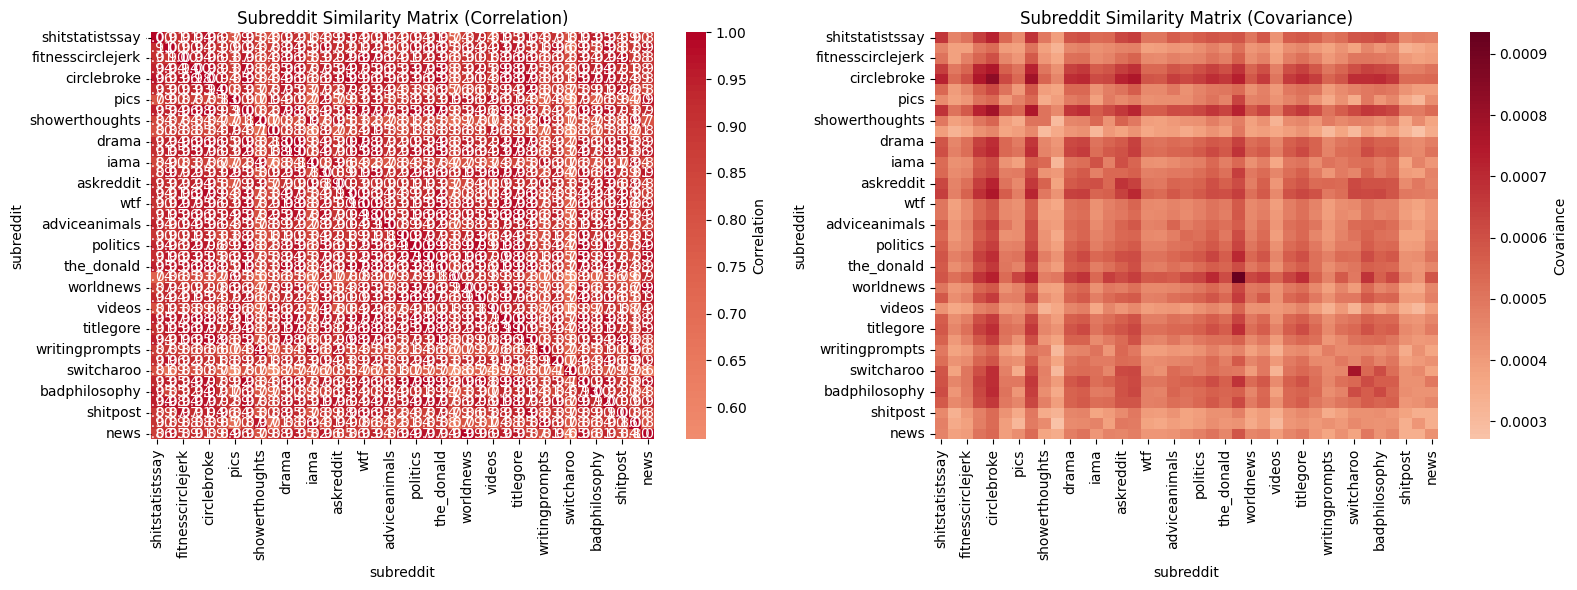

(subreddit          shitstatistssay       nfl  fitnesscirclejerk    bestof  \
 subreddit                                                                   
 shitstatistssay           1.000000  0.911957           0.905232  0.941084   
 nfl                       0.911957  1.000000           0.898000  0.944191   
 fitnesscirclejerk         0.905232  0.898000           1.000000  0.939883   
 bestof                    0.941084  0.944191           0.939883  1.000000   
 circlebroke               0.962657  0.929243           0.958378  0.978609   
 gamingcirclejerk          0.925872  0.899589           0.934858  0.930754   
 pics                      0.787085  0.904582           0.871325  0.870217   
 shitamericanssay          0.948362  0.938115           0.958990  0.978295   
 showerthoughts            0.843771  0.869908           0.843946  0.839201   
 gifs                      0.797789  0.876004           0.882169  0.845796   
 drama                     0.918542  0.941069           0.955058

In [17]:
tsa.calculate_subreddit_similarity_matrix(liwc_df, output_dir = "src/analysis/top_subreddits_analysis_charts", show=True)

# Next steps for top subreddits analysis:<br>
- Interactive 3D representation
- Search for correlation on a smaller scale (i.e. create heatmaps for all pairs of top subreddits, investigate most interesting ones)
- Consider more features like post length, readability, and virality (i.e. upvotes, downvotes, saves, etc.)
- Perform this analysis on a subreddit-level and on a post-level
- Form hypothesis and conduct investigation on qualities that top (i.e. popular / viral) subreddits and posts share